# 03 — What-if Analysis: Nếu giao hàng tốt hơn, review xấu giảm bao nhiêu?
**Model:** Logistic Regression — target `bad_review` (1 = review ≤ 2★).

**Vì sao Logistic Regression?**
- Target nhị phân, cần **xác suất** để mô phỏng kịch bản (what-if = thay đổi input → xem xác suất thay đổi).
- Hệ số diễn giải được thành **odds ratio** → giải thích cho người không chuyên.
- Decision Tree dùng làm mô hình đối chiếu.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, precision_recall_curve, RocCurveDisplay)

In [2]:
df = pd.read_csv("../output/fact_orders_clean.csv", low_memory=False)
df = df[df["in_scope"] == 1].copy()
df.shape

(95560, 54)

## 1. Chuẩn bị feature
- `late_days` = số ngày trễ so với dự kiến (0 nếu không trễ), `early_days` = số ngày sớm. Tách 2 biến vì EDA cho thấy ảnh hưởng **không tuyến tính**: sớm thêm vài ngày gần như không đổi review, còn trễ thì review giảm mạnh.
- Clip ở 30 ngày để vài đơn trễ > 100 ngày không chi phối hệ số (quyết định xử lý ngoại lai từ notebook 01).
- `delivery_days` **không** đưa vào vì ≈ `estimated_days` + `delay_days` (đa cộng tuyến).
- NULL (`handling_days`, `distance_km`, `product_weight_g`) → fill median của tập train.

In [3]:
df["late_days"]  = df["delay_days"].clip(lower=0, upper=30)
df["early_days"] = (-df["delay_days"]).clip(lower=0, upper=30)
df["log_price"]  = np.log1p(df["total_price"])
df["freight_ratio"] = df["freight_ratio"].clip(upper=df["freight_ratio"].quantile(0.99))

features = ["late_days", "early_days", "estimated_days", "handling_days", "freight_ratio",
            "log_price", "distance_km", "same_state", "n_items", "n_sellers", "product_weight_g"]
target = "bad_review"

df[features + [target]].describe().round(2)

,late_days,early_days,estimated_days,handling_days,freight_ratio,log_price,distance_km,same_state,n_items,n_sellers,product_weight_g,bad_review
count,95560.00,95560.00,95560.00,95376.00,95560.00,95560.00,95085.00,95560.00,95560.00,95560.00,95544.0,95560.00
mean,0.61,12.40,23.64,3.20,0.30,4.46,600.30,0.36,1.14,1.01,2107.4,0.13
std,3.12,7.36,8.60,3.45,0.26,0.92,593.14,0.48,0.53,0.12,3763.2,0.33
min,0.00,-0.00,2.01,0.00,0.00,0.62,0.00,0.00,1.00,1.00,0.0,0.00
25%,0.00,7.00,18.32,1.13,0.13,3.85,185.84,0.00,1.00,1.00,300.0,0.00
50%,0.00,12.00,23.21,2.20,0.22,4.47,433.78,0.00,1.00,1.00,700.0,0.00
75%,0.00,17.00,28.37,4.05,0.38,5.02,798.31,1.00,1.00,1.00,1813.0,0.00
max,30.00,30.00,155.14,125.78,1.46,9.51,8677.91,1.00,21.00,5.00,40425.0,1.00


In [4]:
df_num = df[features + [target]]
df_num.corr()[target].sort_values()

early_days         -0.184840
same_state         -0.053053
freight_ratio       0.015894
product_weight_g    0.027576
estimated_days      0.039821
distance_km         0.046783
log_price           0.050622
n_sellers           0.118935
n_items             0.125486
handling_days       0.145710
late_days           0.364180
bad_review          1.000000
Name: bad_review, dtype: float64

In [5]:
x = df[features]
y = df[target].astype(int)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

medians = x_train.median()
x_train = x_train.fillna(medians)
x_test  = x_test.fillna(medians)

# Fit scaler CHỈ trên train, test chỉ transform (tránh rò rỉ dữ liệu)
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s  = scaler.transform(x_test)

print(f"train = {len(x_train):,}, test = {len(x_test):,}, bad_review rate = {y.mean():.1%}")

train = 76,448, test = 19,112, bad_review rate = 12.8%


## 2. Huấn luyện & đánh giá

**Chọn metric**
- Lớp mất cân bằng (~13% review xấu) → **Accuracy gây hiểu lầm**: đoán "không xấu" cho mọi đơn đã đạt ~87%.
- **ROC-AUC** (metric chính): khả năng xếp hạng đơn rủi ro cao hơn đơn rủi ro thấp, không phụ thuộc ngưỡng.
- **PR-AUC**: tập trung vào lớp thiểu số (review xấu), baseline = tỉ lệ review xấu.
- **Recall / Precision / F1** của lớp review xấu tại ngưỡng đã chọn: Recall = bắt được bao nhiêu % khách sẽ không hài lòng (quan trọng để chủ động chăm sóc).

Không dùng `class_weight="balanced"` để xác suất dự đoán giữ đúng thang thực tế (cần cho what-if); thay vào đó **chọn ngưỡng** tối ưu F1 trên tập train.

In [6]:
model = LogisticRegression(max_iter=1000)
model.fit(x_train_s, y_train)

p_train = model.predict_proba(x_train_s)[:, 1]
p_test  = model.predict_proba(x_test_s)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, p_train)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
threshold = thr[np.argmax(f1[:-1])]
print(f"Ngưỡng tối ưu F1 (train): {threshold:.3f}")

Ngưỡng tối ưu F1 (train): 0.217


In [7]:
def evaluate(name, y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return {
        "model"    : name,
        "threshold": round(thr, 3),
        "ROC-AUC"  : roc_auc_score(y_true, prob),
        "PR-AUC"   : average_precision_score(y_true, prob),
        "Accuracy" : accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall"   : recall_score(y_true, pred),
        "F1"       : f1_score(y_true, pred),
    }

results = [
    evaluate("Baseline: luôn đoán 0", y_test, np.zeros(len(y_test)), 0.5),
    evaluate("Logistic (ngưỡng 0.5)", y_test, p_test, 0.5),
    evaluate("Logistic (ngưỡng tối ưu)", y_test, p_test, threshold),
]

### Mô hình đối chiếu: Decision Tree

In [8]:
tree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=42)
tree.fit(x_train, y_train)
p_tree_train = tree.predict_proba(x_train)[:, 1]
p_tree = tree.predict_proba(x_test)[:, 1]

prec_t, rec_t, thr_t = precision_recall_curve(y_train, p_tree_train)
f1_t = 2 * prec_t * rec_t / (prec_t + rec_t + 1e-9)
threshold_tree = thr_t[np.argmax(f1_t[:-1])]

results.append(evaluate("Decision Tree (ngưỡng tối ưu)", y_test, p_tree, threshold_tree))
metrics = pd.DataFrame(results).set_index("model").round(3)
metrics

,threshold,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
model,,,,,,,
Baseline: luôn đoán 0,0.500,0.500,0.128,0.872,0.000,0.000,0.000
Logistic (ngưỡng 0.5),0.500,0.753,0.448,0.889,0.728,0.217,0.334
Logistic (ngưỡng tối ưu),0.217,0.753,0.448,0.881,0.548,0.412,0.470
Decision Tree (ngưỡng tối ưu),0.241,0.736,0.442,0.869,0.487,0.455,0.471


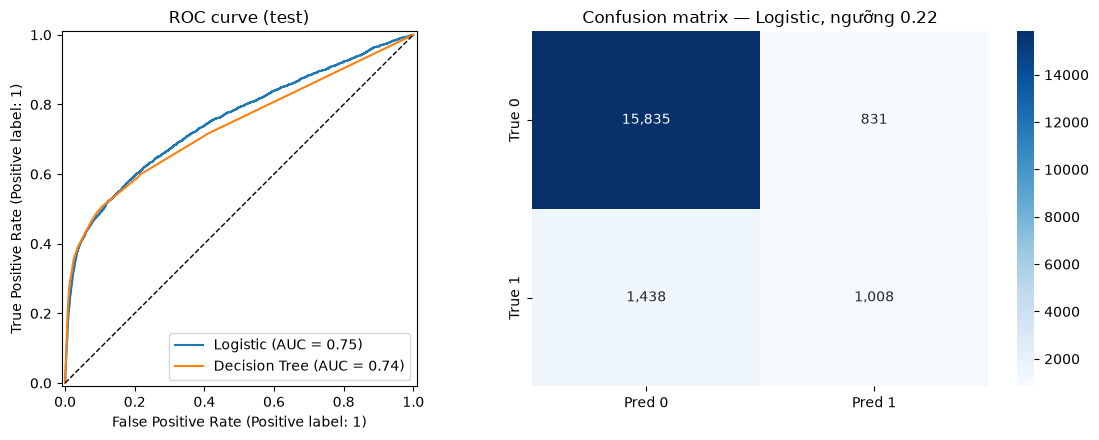

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
RocCurveDisplay.from_predictions(y_test, p_test, name="Logistic", ax=ax[0])
RocCurveDisplay.from_predictions(y_test, p_tree, name="Decision Tree", ax=ax[0])
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_title("ROC curve (test)")

cm = confusion_matrix(y_test, (p_test >= threshold).astype(int))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", ax=ax[1],
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
ax[1].set_title(f"Confusion matrix — Logistic, ngưỡng {threshold:.2f}")
plt.tight_layout(); plt.show()

In [10]:
# Xác suất có khớp thực tế không? (quan trọng vì what-if dùng xác suất)
calib = (pd.DataFrame({"prob": p_test, "actual": y_test.values})
           .assign(bin=lambda d: pd.qcut(d["prob"], 10, duplicates="drop"))
           .groupby("bin", observed=True)[["prob", "actual"]].mean())
print(f"Mean predicted = {p_test.mean():.3f}, actual = {y_test.mean():.3f}")
calib.round(3)

Mean predicted = 0.130, actual = 0.128


,prob,actual
bin,,
"(0.030600000000000002, 0.0585]",0.054,0.044
"(0.0585, 0.0645]",0.062,0.064
"(0.0645, 0.07]",0.067,0.055
"(0.07, 0.0761]",0.073,0.066
"(0.0761, 0.0835]",0.080,0.061
"(0.0835, 0.0938]",0.088,0.079
"(0.0938, 0.109]",0.100,0.096
"(0.109, 0.134]",0.120,0.116
"(0.134, 0.209]",0.162,0.162


## 3. Diễn giải hệ số (odds ratio)

In [11]:
coef = (pd.DataFrame({"feature": features, "coef": model.coef_[0]})
          .assign(odds_ratio_per_1sd=lambda d: np.exp(d["coef"]),
                  sd=scaler.scale_)
          .sort_values("coef", ascending=False))
coef.round(3)

,feature,coef,odds_ratio_per_1sd,sd
0,late_days,0.607,1.835,3.078
2,estimated_days,0.414,1.514,8.581
8,n_items,0.238,1.269,0.527
9,n_sellers,0.208,1.231,0.122
5,log_price,0.093,1.097,0.917
4,freight_ratio,0.069,1.071,0.261
3,handling_days,0.060,1.062,3.444
7,same_state,0.005,1.005,0.480
10,product_weight_g,-0.011,0.990,3757.700
6,distance_km,-0.111,0.895,592.369


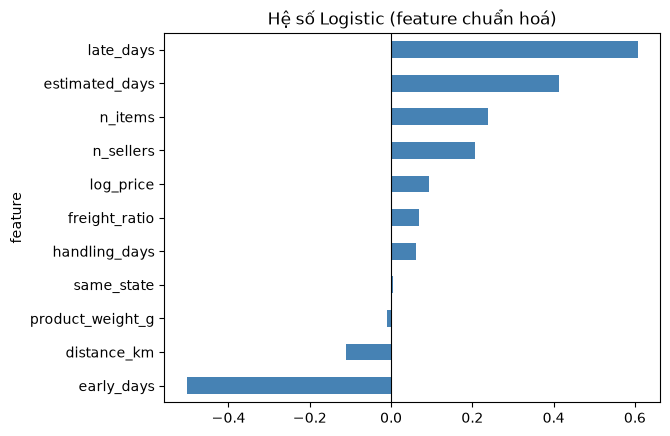

In [12]:
coef.set_index("feature")["coef"].sort_values().plot(kind="barh", color="steelblue",
                                                     title="Hệ số Logistic (feature chuẩn hoá)")
plt.axvline(0, color="black", lw=0.8); plt.show()

Đọc bảng: `odds_ratio_per_1sd` = odds review xấu nhân lên bao nhiêu lần khi feature tăng 1 độ lệch chuẩn (`sd`), giữ các feature khác không đổi.

## 4. What-if: mô phỏng kịch bản
Áp dụng lên **toàn bộ đơn trễ** trong phạm vi phân tích, so sánh xác suất review xấu dự đoán trước và sau khi thay đổi:
1. Giảm trễ 3 ngày
2. Giao đúng hạn (late_days = 0)
3. Giảm phí ship 20% (freight_ratio × 0.8)
4. Đơn nhiều người bán → chỉ 1 người bán (n_sellers = 1) — áp dụng cho đơn có ≥2 người bán

In [13]:
x_all = df[features].fillna(medians)

def predict(frame):
    return model.predict_proba(scaler.transform(frame))[:, 1]

def scenario(name, mask, change):
    base = x_all[mask]
    new  = change(base.copy())
    p0, p1 = predict(base), predict(new)
    return {
        "scenario"              : name,
        "orders"                : int(mask.sum()),
        "actual_bad_rate"       : df.loc[mask, target].mean(),
        "pred_bad_rate_before"  : p0.mean(),
        "pred_bad_rate_after"   : p1.mean(),
        "expected_bad_before"   : p0.sum(),
        "expected_bad_after"    : p1.sum(),
        "bad_reviews_avoided"   : p0.sum() - p1.sum(),
    }

late  = df["late_days"] > 0
multi = df["n_sellers"] >= 2

scenarios = pd.DataFrame([
    scenario("Late orders: reduce delay by 3 days", late,
             lambda d: d.assign(late_days=(d["late_days"] - 3).clip(lower=0))),
    scenario("Late orders: deliver on time", late,
             lambda d: d.assign(late_days=0)),
    scenario("Late orders: freight -20%", late,
             lambda d: d.assign(freight_ratio=d["freight_ratio"] * 0.8)),
    scenario("All orders: freight -20%", pd.Series(True, index=df.index),
             lambda d: d.assign(freight_ratio=d["freight_ratio"] * 0.8)),
    scenario("Multi-seller orders: single seller", multi,
             lambda d: d.assign(n_sellers=1)),
])
scenarios["relative_change"] = scenarios["pred_bad_rate_after"] / scenarios["pred_bad_rate_before"] - 1
scenarios.round(3)

,scenario,orders,actual_bad_rate,pred_bad_rate_before,pred_bad_rate_after,expected_bad_before,expected_bad_after,bad_reviews_avoided,relative_change
0,Late orders: reduce delay by 3 days,6378,0.624,0.523,0.432,3335.867,2756.218,579.650,-0.174
1,Late orders: deliver on time,6378,0.624,0.523,0.196,3335.867,1251.365,2084.503,-0.625
2,Late orders: freight -20%,6378,0.624,0.523,0.520,3335.867,3317.576,18.292,-0.005
3,All orders: freight -20%,95560,0.128,0.128,0.127,12263.526,12123.625,139.900,-0.011
4,Multi-seller orders: single seller,1258,0.471,0.475,0.150,597.124,189.253,407.871,-0.683


In [14]:
# Ảnh hưởng lên điểm toàn hệ thống: % review xấu toàn bộ đơn nếu mọi đơn trễ được giao đúng hạn
total_expected = predict(x_all).sum()
avoided = scenarios.loc[scenarios["scenario"] == "Late orders: deliver on time", "bad_reviews_avoided"].iloc[0]
print(f"% review xấu dự đoán toàn hệ thống: {total_expected / len(df):.1%} -> {(total_expected - avoided) / len(df):.1%}")

% review xấu dự đoán toàn hệ thống: 12.8% -> 10.7%


### Đường cong what-if: xác suất review xấu theo số ngày trễ (đơn giao đúng ngày dự kiến làm mốc 0, các feature khác = median)

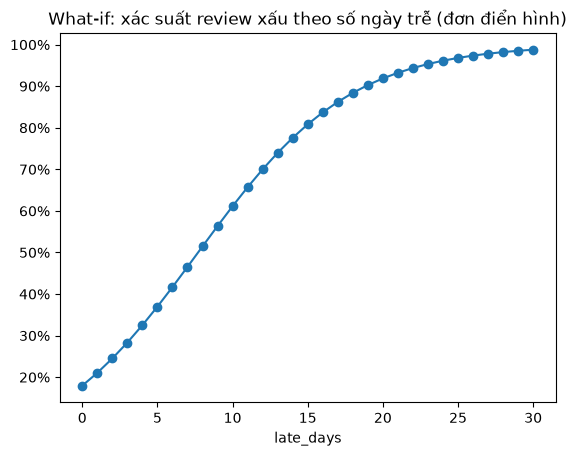

,late_days,prob_bad_review
0,0,0.180
1,1,0.210
3,3,0.283
5,5,0.370
7,7,0.465
10,10,0.611
15,15,0.808
20,20,0.919
30,30,0.988


In [15]:
typical = x_all.median().to_frame().T
grid = pd.concat([typical.assign(late_days=d, early_days=0) for d in range(0, 31)], ignore_index=True)
curve = pd.DataFrame({"late_days": range(0, 31), "prob_bad_review": predict(grid)})

ax = curve.plot(x="late_days", y="prob_bad_review", marker="o", legend=False,
                title="What-if: xác suất review xấu theo số ngày trễ (đơn điển hình)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.show()
curve.iloc[[0, 1, 3, 5, 7, 10, 15, 20, 30]].round(3)

### Một đơn hàng cụ thể

In [16]:
order = x_all[late].iloc[[0]].copy()
cases = pd.DataFrame({
    "as-is"          : order.iloc[0],
    "delay -3 days"  : order.assign(late_days=(order["late_days"] - 3).clip(lower=0)).iloc[0],
    "on time"        : order.assign(late_days=0).iloc[0],
}).T
cases["prob_bad_review"] = predict(cases[features])
cases[["late_days", "early_days", "freight_ratio", "n_sellers", "prob_bad_review"]].round(3)

,late_days,early_days,freight_ratio,n_sellers,prob_bad_review
as-is,2.0,0.0,0.539,1.0,0.175
delay -3 days,0.0,0.0,0.539,1.0,0.125
on time,0.0,0.0,0.539,1.0,0.125


### Bảng what-if cho Power BI: giảm trễ X ngày cho mọi đơn trễ
Dùng cho thanh trượt "Giảm trễ (ngày)" ở trang What-if của dashboard.

In [17]:
p_all = predict(x_all)
reduction = []
for k in range(0, 16):
    new = x_all.copy()
    new.loc[late, "late_days"] = (new.loc[late, "late_days"] - k).clip(lower=0)
    p_new = predict(new)
    reduction.append({
        "reduce_days"          : k,
        "late_orders_pred_bad_rate": p_new[late.values].mean(),
        "system_pred_bad_rate" : p_new.mean(),
        "expected_bad_reviews" : p_new.sum(),
        "bad_reviews_avoided"  : p_all.sum() - p_new.sum(),
    })
reduction = pd.DataFrame(reduction)
reduction.round(3)

,reduce_days,late_orders_pred_bad_rate,system_pred_bad_rate,expected_bad_reviews,bad_reviews_avoided
0,0,0.523,0.128,12263.526,0.000
1,1,0.489,0.126,12046.048,217.478
2,2,0.459,0.124,11855.691,407.835
3,3,0.432,0.122,11683.876,579.650
4,4,0.408,0.121,11529.113,734.413
5,5,0.386,0.119,11389.500,874.026
6,6,0.366,0.118,11265.026,998.500
7,7,0.349,0.117,11154.657,1108.869
8,8,0.334,0.116,11059.770,1203.756
9,9,0.321,0.115,10975.587,1287.939


In [18]:
scenarios.to_csv("../output/what_if_scenarios.csv", index=False)
curve.to_csv("../output/what_if_delay_curve.csv", index=False)
coef.to_csv("../output/model_coefficients.csv", index=False)
metrics.to_csv("../output/model_metrics.csv")
reduction.to_csv("../output/what_if_reduction.csv", index=False)

## 5. Kết luận & hạn chế
**Model**
- Logistic: ROC-AUC ≈ 0,75, PR-AUC ≈ 0,45 (baseline 0,13). Tại ngưỡng tối ưu (~0,22): Recall ≈ 41%, Precision ≈ 55%. Decision Tree cho kết quả tương đương (AUC ≈ 0,74) → chọn Logistic vì diễn giải được và xác suất khớp thực tế (TB dự đoán 13,0% vs thực tế 12,8%).
- Accuracy của baseline "luôn đoán 0" đã là 87% → minh chứng vì sao không dùng Accuracy.

**What-if (trên 6.378 đơn trễ)**
- Giao đúng hạn: % review xấu dự đoán 52% → 20%, tránh ~2.100 review xấu; toàn hệ thống 12,8% → 10,7%.
- Giảm trễ 3 ngày: 52% → 43% (~580 review xấu).
- Giảm phí ship 20%: gần như không đổi (−0,5%) → phí ship **không** phải đòn bẩy.
- `late_days` có hệ số lớn nhất: mỗi +1 SD (~3 ngày trễ) nhân odds review xấu ×1,8.

**Hạn chế**
- Model **đánh giá thấp** rủi ro của đơn trễ (dự đoán 52% vs thực tế 62%) do quan hệ trễ → review không tuyến tính hoàn toàn → con số "tránh được" là ước lượng **thận trọng**.
- Kịch bản "1 người bán" chỉ mang tính tham khảo: n_sellers đi cùng nhiều yếu tố khác (số item, cách giao tách kiện).
- What-if là **ước lượng theo mô hình tương quan**, không phải thử nghiệm nhân quả: các yếu tố không quan sát được (chất lượng sản phẩm, người bán) có thể đi cùng giao trễ.
- Model chỉ dùng biến giao hàng/đơn hàng; không có nội dung sản phẩm, nên ROC-AUC bị giới hạn — nhiều review xấu đến từ lý do khác ngoài giao hàng.